# Work with Inner Merged DFs
I have an idea that the outcomes might be different if we would use only the limited data. I want to test this approach as well.

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

1. Reading all .csv files into dataframes:

In [35]:
df_orders = pd.read_csv('../data_csv/orders.csv')
df_orders.columns = df_orders.columns.str.lower()
df_orders.columns = df_orders.columns.str.replace(' ','_')
df_orders['total_items'] = df_orders.groupby("order_id")["quantity"].transform("sum")
df_orders = df_orders.drop(columns=['customer_id', 'customer_name','country/region', 
'city','state', 'postal_code','category', 'product_id', 'sales', 'discount','profit', 'sub-category', 'quantity'])
df_orders.rename(columns={"index": "row_id"}, inplace=True)
df_orders.to_csv('../data_csv/orders_min.csv')

df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   row_id          9994 non-null   int64
 1   order_id        9994 non-null   str  
 2   order_date      9994 non-null   str  
 3   ship_mode       9994 non-null   str  
 4   origin_channel  9994 non-null   str  
 5   region          9994 non-null   str  
 6   total_items     9994 non-null   int64
dtypes: int64(2), str(5)
memory usage: 546.7 KB


In [37]:
df_interns = pd.read_csv('../data_csv/intern_unique.csv')
df_interns = df_interns.drop(columns=['Unnamed: 0','ready_ship_year','ready_ship_month', 
'ready_ship_weekday', 'pickup_year', 'pickup_month', 'pickup_weekday'])
df_interns.to_csv('../data_csv/interns_min.csv')
df_interns.info()

<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            204 non-null    str  
 1   ready_to_ship_date  204 non-null    str  
 2   pickup_date         204 non-null    str  
dtypes: str(3)
memory usage: 4.9 KB


In [38]:
df_process = pd.read_csv('../data_csv/process_clean.csv')
df_process = df_process.drop(columns=['order_id','order_date','order_year','order_month', 'order_weekday',
'truck_year', 'truck_month', 'truck_weekday'])
df_process.rename(columns={"ship_mode": "truck_ship_mode"}, inplace=True)
df_process.to_csv('../data_csv/process_min.csv')
df_process.info()

<class 'pandas.DataFrame'>
RangeIndex: 5899 entries, 0 to 5898
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              5899 non-null   int64
 1   on_truck_scan_date  5899 non-null   str  
 2   truck_ship_mode     5899 non-null   str  
dtypes: int64(1), str(2)
memory usage: 138.4 KB


In [39]:
df_scan = pd.read_csv('../data_csv/campaign_clean.csv')
df_scan = df_scan.drop(columns=['customer_name', 'arrival_year', 'arrival_month','arrival_day', 'arrival_weekday'])
df_scan.to_csv('../data_csv/scan_min.csv')
df_scan.info()

<class 'pandas.DataFrame'>
RangeIndex: 333 entries, 0 to 332
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   order_id           333 non-null    str  
 1   arrival_scan_date  333 non-null    str  
dtypes: str(2)
memory usage: 5.3 KB


In [40]:
df_short = df_orders.merge(df_process, how='inner', on='row_id')

In [41]:
print(df_short[["order_id"]].duplicated().value_counts())
print(df_short.info())

False    3002
True     2897
Name: count, dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 5899 entries, 0 to 5898
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   row_id              5899 non-null   int64
 1   order_id            5899 non-null   str  
 2   order_date          5899 non-null   str  
 3   ship_mode           5899 non-null   str  
 4   origin_channel      5899 non-null   str  
 5   region              5899 non-null   str  
 6   total_items         5899 non-null   int64
 7   on_truck_scan_date  5899 non-null   str  
 8   truck_ship_mode     5899 non-null   str  
dtypes: int64(2), str(7)
memory usage: 414.9 KB
None


In [42]:
df_unique = df_short.drop_duplicates(subset="order_id", keep="first")
df_unique = df_unique.drop(columns=['row_id'])

In [43]:
df_unique.info()

<class 'pandas.DataFrame'>
Index: 3002 entries, 0 to 5895
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            3002 non-null   str  
 1   order_date          3002 non-null   str  
 2   ship_mode           3002 non-null   str  
 3   origin_channel      3002 non-null   str  
 4   region              3002 non-null   str  
 5   total_items         3002 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
dtypes: int64(1), str(7)
memory usage: 211.1 KB


In [30]:
df_unique_add = df_unique.merge(df_interns,how = 'outer', on='order_id')
df_unique_add.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            3002 non-null   str  
 1   order_date          3002 non-null   str  
 2   ship_mode           3002 non-null   str  
 3   origin_channel      3002 non-null   str  
 4   region              3002 non-null   str  
 5   total_items         3002 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
 8   ready_to_ship_date  204 non-null    str  
 9   pickup_date         204 non-null    str  
dtypes: int64(1), str(9)
memory usage: 234.7 KB


In [ ]:
df_unique_all = df_unique_add.merge(df_scan, how='outer', on='order_id')
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   order_id            3002 non-null   str  
 1   order_date          3002 non-null   str  
 2   ship_mode           3002 non-null   str  
 3   origin_channel      3002 non-null   str  
 4   region              3002 non-null   str  
 5   total_items         3002 non-null   int64
 6   on_truck_scan_date  3002 non-null   str  
 7   truck_ship_mode     3002 non-null   str  
 8   ready_to_ship_date  204 non-null    str  
 9   pickup_date         204 non-null    str  
 10  arrival_scan_date   333 non-null    str  
dtypes: int64(1), str(10)
memory usage: 258.1 KB


In [45]:
df_unique_all.to_csv('../data_csv/working_file.csv')

Dealimg with formats:

In [50]:
df_unique_all["order_date"] = pd.to_datetime(df_unique_all["order_date"])
df_unique_all["ready_to_ship_date"] = pd.to_datetime(df_unique_all["ready_to_ship_date"])
df_unique_all["pickup_date"] = pd.to_datetime(df_unique_all["pickup_date"])
df_unique_all["on_truck_scan_date"] = pd.to_datetime(df_unique_all["on_truck_scan_date"])
df_unique_all["arrival_scan_date"] = pd.to_datetime(df_unique_all["arrival_scan_date"])
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            3002 non-null   str           
 1   order_date          3002 non-null   datetime64[us]
 2   ship_mode           3002 non-null   str           
 3   origin_channel      3002 non-null   str           
 4   region              3002 non-null   str           
 5   total_items         3002 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
dtypes: datetime64[us](5), int64(1), str(5)
memory usage: 258.1 KB


New Variables / KPIs in Business Days

In [ ]:
# processing_time
# calculated as:
# order date -------> ready to ship
mask = df_unique_all["order_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "process_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   order_id            3002 non-null   str           
 1   order_date          3002 non-null   datetime64[us]
 2   ship_mode           3002 non-null   str           
 3   origin_channel      3002 non-null   str           
 4   region              3002 non-null   str           
 5   total_items         3002 non-null   int64         
 6   on_truck_scan_date  3002 non-null   datetime64[us]
 7   truck_ship_mode     3002 non-null   str           
 8   ready_to_ship_date  204 non-null    datetime64[us]
 9   pickup_date         204 non-null    datetime64[us]
 10  arrival_scan_date   333 non-null    datetime64[us]
 11  process_days_biz    204 non-null    float64       
dtypes: datetime64[us](5), float64(1), int64(1), str(5)
memory usage: 281.6 KB


In [ ]:
# truck waiting days
# calculated as:
# ready to ship ------> pickup date
# according to interns
mask = df_unique_all["pickup_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "truck_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "pickup_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             3002 non-null   str           
 1   order_date           3002 non-null   datetime64[us]
 2   ship_mode            3002 non-null   str           
 3   origin_channel       3002 non-null   str           
 4   region               3002 non-null   str           
 5   total_items          3002 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
dtypes: datetime64[us](5), float64(2), int64(1), 

In [54]:
# warehouse waiting days: pretty similar to truck waiting days; calculated from a different variable: 
# reday to ship ------> on truck scan
mask = df_unique_all["on_truck_scan_date"].notna() & df_unique_all["ready_to_ship_date"].notna()

df_unique_all.loc[mask, "war_wait_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "ready_to_ship_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]")
)
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             3002 non-null   str           
 1   order_date           3002 non-null   datetime64[us]
 2   ship_mode            3002 non-null   str           
 3   origin_channel       3002 non-null   str           
 4   region               3002 non-null   str           
 5   total_items          3002 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

In [55]:
# transport days
# calculated as:
# on truck scan ------> arrival scan
mask = df_unique_all["arrival_scan_date"].notna() & df_unique_all["on_truck_scan_date"].notna()

df_unique_all.loc[mask, "transp_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "on_truck_scan_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             3002 non-null   str           
 1   order_date           3002 non-null   datetime64[us]
 2   ship_mode            3002 non-null   str           
 3   origin_channel       3002 non-null   str           
 4   region               3002 non-null   str           
 5   total_items          3002 non-null   int64         
 6   on_truck_scan_date   3002 non-null   datetime64[us]
 7   truck_ship_mode      3002 non-null   str           
 8   ready_to_ship_date   204 non-null    datetime64[us]
 9   pickup_date          204 non-null    datetime64[us]
 10  arrival_scan_date    333 non-null    datetime64[us]
 11  process_days_biz     204 non-null    float64       
 12  truck_wait_days_biz  204 non-null    float64       
 13  war_wait_days_biz    204 non-null    float64

In [56]:
# total delivery time
# calculated:
# order date ------> arrival scan

mask = df_unique_all["order_date"].notna() & df_unique_all["arrival_scan_date"].notna()

df_unique_all.loc[mask, "total_delivery_days_biz"] = np.busday_count(
    df_unique_all.loc[mask, "order_date"].values.astype("datetime64[D]"),
    df_unique_all.loc[mask, "arrival_scan_date"].values.astype("datetime64[D]")
)

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 3002 non-null   str           
 1   order_date               3002 non-null   datetime64[us]
 2   ship_mode                3002 non-null   str           
 3   origin_channel           3002 non-null   str           
 4   region                   3002 non-null   str           
 5   total_items              3002 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

Add the days of the week for each action (to see distributions later and to get rid of the date columns)

In [ ]:
# order:
df_unique_all["order_weekday"]=df_unique_all["order_date"].dt.dayofweek
# became integer because there are no missing values

# ready to ship (warehouse):
df_unique_all["ready_ship_weekday"]=df_unique_all["ready_to_ship_date"].dt.dayofweek
# became float because there are missing values

# pickup date (interns):
df_unique_all["pickup_weekday"]=df_unique_all["pickup_date"].dt.dayofweek

# on truck scan (logistics company):
df_unique_all["on_truck_weekday"]=df_unique_all["on_truck_scan_date"].dt.dayofweek

# arrival scan (user):
df_unique_all["arrival_weekday"]=df_unique_all["arrival_scan_date"].dt.dayofweek

df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   order_id                 3002 non-null   str           
 1   order_date               3002 non-null   datetime64[us]
 2   ship_mode                3002 non-null   str           
 3   origin_channel           3002 non-null   str           
 4   region                   3002 non-null   str           
 5   total_items              3002 non-null   int64         
 6   on_truck_scan_date       3002 non-null   datetime64[us]
 7   truck_ship_mode          3002 non-null   str           
 8   ready_to_ship_date       204 non-null    datetime64[us]
 9   pickup_date              204 non-null    datetime64[us]
 10  arrival_scan_date        333 non-null    datetime64[us]
 11  process_days_biz         204 non-null    float64       
 12  truck_wait_days_biz      204 non-null    floa

In [58]:
df_unique_all = df_unique_all.drop(columns=['order_date','on_truck_scan_date', 'ready_to_ship_date',
                                            'pickup_date', 'arrival_scan_date'])

In [59]:
df_unique_all.info()

<class 'pandas.DataFrame'>
RangeIndex: 3002 entries, 0 to 3001
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 3002 non-null   str    
 1   ship_mode                3002 non-null   str    
 2   origin_channel           3002 non-null   str    
 3   region                   3002 non-null   str    
 4   total_items              3002 non-null   int64  
 5   truck_ship_mode          3002 non-null   str    
 6   process_days_biz         204 non-null    float64
 7   truck_wait_days_biz      204 non-null    float64
 8   war_wait_days_biz        204 non-null    float64
 9   transp_days_biz          333 non-null    float64
 10  total_delivery_days_biz  333 non-null    float64
 11  order_weekday            3002 non-null   int32  
 12  ready_ship_weekday       204 non-null    float64
 13  pickup_weekday           204 non-null    float64
 14  on_truck_weekday         3002 non-n

## Distribution of Orders by Weekdays

--------------------------- Days when the orders are registered in the system:       ---------------------------
 order_weekday
0    0.173218
1    0.172552
2    0.171552
3    0.182212
4    0.141239
5    0.060959
6    0.098268
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/2992268221.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


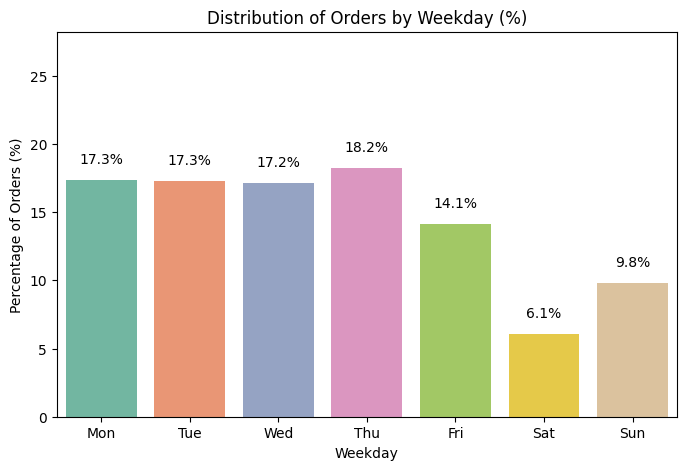

In [96]:
weekday_counts = df_unique_all["order_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Days when the orders are registered in the system: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


In [71]:
df_unique_all.columns

Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
       'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
       'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
       'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
       'on_truck_weekday', 'arrival_weekday'],
      dtype='str')

--------------------------- Days on which the shipment is marked ready in the warehouse:       ---------------------------
 ready_ship_weekday
0.0    0.455882
1.0    0.142157
2.0    0.112745
3.0    0.137255
4.0    0.151961
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/3810739824.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


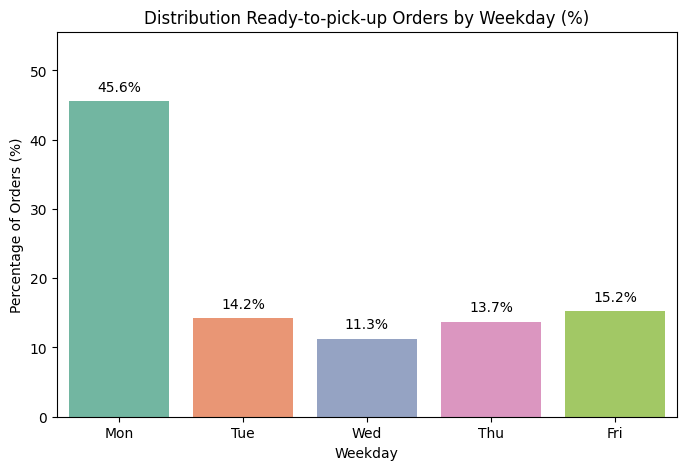

In [95]:
weekday_counts = df_unique_all["ready_ship_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Days on which the shipment is marked ready in the warehouse: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"] # they don't work on Sat and Sun + I checked

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution Ready-to-pick-up Orders by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Pickup days registered in the database:       ---------------------------
 pickup_weekday
0.0    0.196078
1.0    0.004902
2.0    0.455882
3.0    0.083333
4.0    0.259804
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/2300421272.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


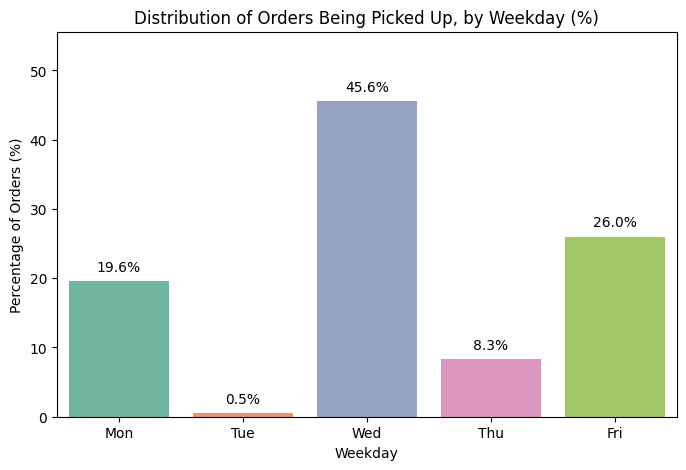

In [ ]:
weekday_counts = df_unique_all["pickup_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Pickup days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Being Picked Up, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Truck Scan Days registered in the database:       ---------------------------
 on_truck_weekday
0    0.182545
1    0.025650
2    0.551299
3    0.015323
4    0.225183
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/932160166.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


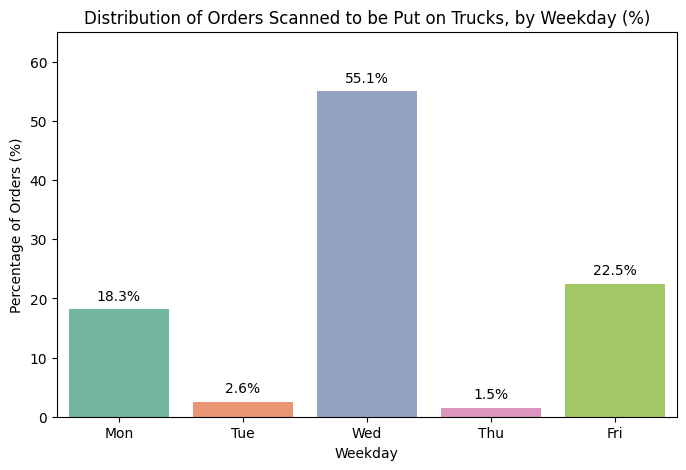

In [ ]:
# Index(['order_id', 'ship_mode', 'origin_channel', 'region', 'total_items',
#        'truck_ship_mode', 'process_days_biz', 'truck_wait_days_biz',
#        'war_wait_days_biz', 'transp_days_biz', 'total_delivery_days_biz',
#        'order_weekday', 'ready_ship_weekday', 'pickup_weekday',
#        'on_truck_weekday', 'arrival_weekday'],

weekday_counts = df_unique_all["on_truck_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Truck Scan Days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Orders Scanned to be Put on Trucks, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()


--------------------------- Arrival Days registered in the database:       ---------------------------
 arrival_weekday
0.0    0.645646
1.0    0.120120
2.0    0.060060
3.0    0.057057
4.0    0.117117
Name: proportion, dtype: float64 
---------------------------


/var/folders/qh/v2kdryds3xz7f7dzt5_z27dh0000gn/T/ipykernel_1219/4180702330.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")


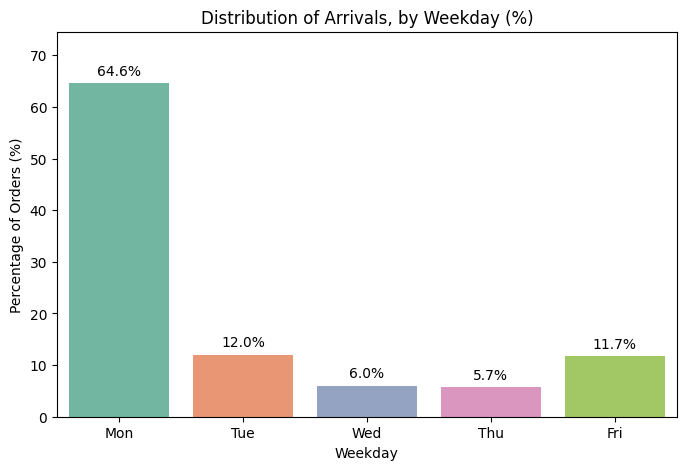

In [ ]:
weekday_counts = df_unique_all["arrival_weekday"].value_counts(normalize=True).sort_index()
print(f'--------------------------- Arrival Days registered in the database: \
      ---------------------------\n {weekday_counts} \n---------------------------')
weekday_labels = ["Mon","Tue","Wed","Thu","Fri"]

weekday_percent = weekday_counts * 100

plt.figure(figsize=(8,5))
ax = sns.barplot(x=weekday_labels, y=weekday_percent.values, palette="Set2")

# Add percentage labels on top of bars
for i, pct in enumerate(weekday_percent.values):
    ax.text(i, pct + 1, f"{pct:.1f}%", ha='center', va='bottom', fontsize=10)

plt.ylabel("Percentage of Orders (%)")
plt.xlabel("Weekday")
plt.title("Distribution of Arrivals, by Weekday (%)")
plt.ylim(0, weekday_percent.max() + 10)  # add space for labels
plt.show()